
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 400.  Construct portfolios from the 400 stocks in the S&P 400 mid cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp400-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AA,Alcoa,US Stocks:Materials,-72.96,-43.48,49.12,41.08,9.35,4.87,41.03,25.42,53.01,50.99,54.57,9.35,50.99,0.18
1,AAL,American Airlines Group,US Stocks:Industrials,246.43,31.81,35.11,28.15,-2.50,-6.12,55.68,34.85,52.40,45.50,43.25,-2.50,45.50,-113.75
2,AAON,AAON,US Stocks:Industrials,5.58,-7.44,8.32,2.59,9.56,17.50,59.09,48.62,71.07,57.52,50.26,9.56,57.52,0.17
3,ACI,Albertsons,US Stocks:Consumer Staples,-73.94,-49.21,-38.51,-36.14,-16.24,-2.56,83.08,74.20,22.12,18.98,28.18,-16.24,18.98,-308.24
4,ACM,AECOM,US Stocks:Industrials,-40.18,-44.93,-35.65,-34.51,-5.67,3.95,31.93,15.51,33.67,28.10,26.23,-5.67,28.10,-159.33
5,ADC,Agree Realty,US Stocks:Real Estate,16.04,26.91,11.27,15.65,9.58,5.56,20.88,9.06,15.51,17.35,17.93,9.58,17.35,0.55
6,AEIS,Advanced Energy,US Stocks:Technology,-66.79,8.25,93.20,78.20,33.02,22.54,83.71,54.68,59.41,44.13,40.53,33.02,44.13,0.75
7,AFG,American Financial Group,US Stocks:Financials,47.35,27.86,18.72,20.93,11.94,11.04,17.29,9.02,18.89,19.47,20.85,11.94,19.47,0.61
8,AGCO,AGCO,US Stocks:Industrials,-22.39,-8.88,0.50,6.67,-6.70,0.07,45.64,34.70,32.27,28.73,33.41,-6.70,28.73,-192.49
9,AHR,American Healthcare REIT,US Stocks:Real Estate,54.73,47.67,49.56,58.78,49.56,49.56,27.75,13.25,24.64,29.74,29.74,49.56,29.74,1.67


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
346,TLN,Talen Energy,US Stocks:Utilities,-20.26,-17.07,-7.94,-11.87,85.02,85.02,55.87,38.26,31.12,37.01,36.53,85.02,37.01,2.30
354,TTMI,TTM Technologies,US Stocks:Technology,-50.20,38.96,138.07,121.48,100.93,53.13,106.48,68.94,85.06,67.08,57.74,100.93,67.08,1.50
9,AHR,American Healthcare REIT,US Stocks:Real Estate,54.73,47.67,49.56,58.78,49.56,49.56,27.75,13.25,24.64,29.74,29.74,49.56,29.74,1.67
236,NEU,NewMarket Corporation,US Stocks:Materials,186.60,80.20,28.12,15.17,27.48,26.23,41.47,13.82,29.78,25.80,23.29,27.48,25.80,1.07
90,CRS,Carpenter Technology,US Stocks:Industrials,135.70,130.95,83.49,92.56,108.30,70.17,46.98,30.68,48.95,47.02,48.63,108.30,47.02,2.30
53,BTSG,BrightSpring Health Services,US Stocks:Healthcare,424.87,239.57,262.59,238.72,262.59,262.59,39.07,20.64,27.44,49.43,49.43,262.59,49.43,5.31
343,THG,Hanover Insurance,US Stocks:Financials,187.83,84.10,41.09,43.61,30.01,14.52,27.83,15.09,21.38,19.38,19.95,30.01,19.38,1.55
110,DTM,DT Midstream,US Stocks:Energy,-3.33,24.15,39.51,40.64,42.80,32.63,22.15,15.13,21.54,20.65,22.47,42.80,20.65,2.07
83,COKE,Coca-Cola Consolidated,US Stocks:Consumer Staples,-21.48,62.10,66.44,66.63,45.52,37.18,37.94,23.68,44.65,39.19,41.23,45.52,39.19,1.16
156,GHC,Graham Holdings,US Stocks:Consumer Discretionary,29.80,16.08,33.53,35.84,29.60,14.35,22.39,11.23,26.77,22.20,21.96,29.60,22.20,1.33


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,TLN,TTMI,AHR,NEU,CRS,BTSG,THG,DTM,COKE,GHC,NYT,Ranked Portfolio
Annual Returns,85.02,100.93,49.56,27.48,108.30,262.59,30.01,42.80,45.52,29.60,24.74,61.81
Std Dev,37.01,67.08,29.74,25.80,47.02,49.43,19.38,20.65,39.19,22.20,25.15,18.22
Sharpe Ratio,2.30,1.50,1.67,1.07,2.30,5.31,1.55,2.07,1.16,1.33,0.98,3.39
Weight,0.04,0.02,0.13,0.12,0.06,0.08,0.11,0.11,0.07,0.15,0.10,1.00
Worst Typical Down Year,11.00,-33.23,-9.92,-24.12,14.26,163.73,-8.75,1.50,-32.86,-14.80,-25.56,25.38
Black Swan,-26.01,-100.31,-39.66,-49.92,-32.76,114.30,-28.13,-19.15,-72.05,-37.00,-50.71,7.16


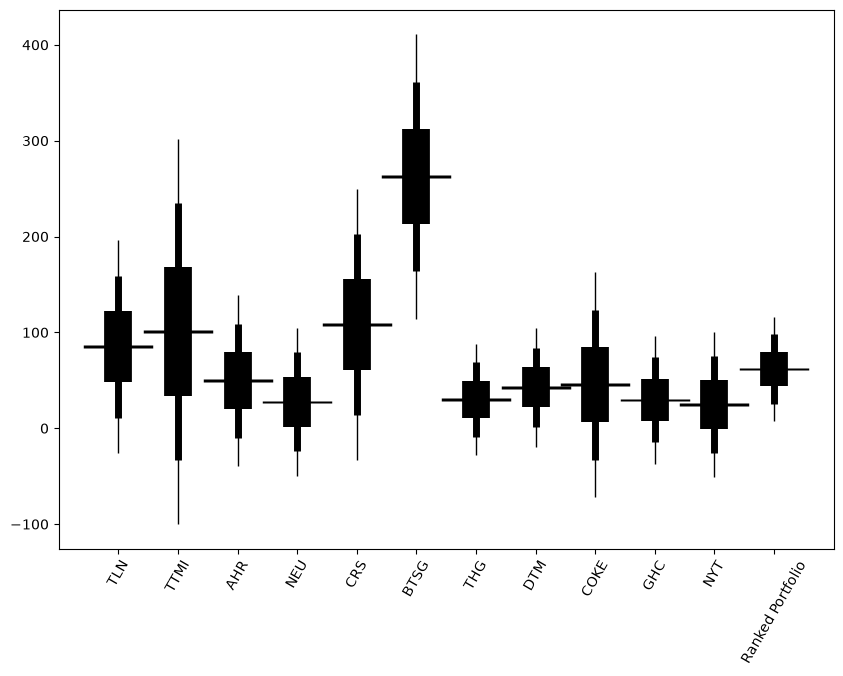

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

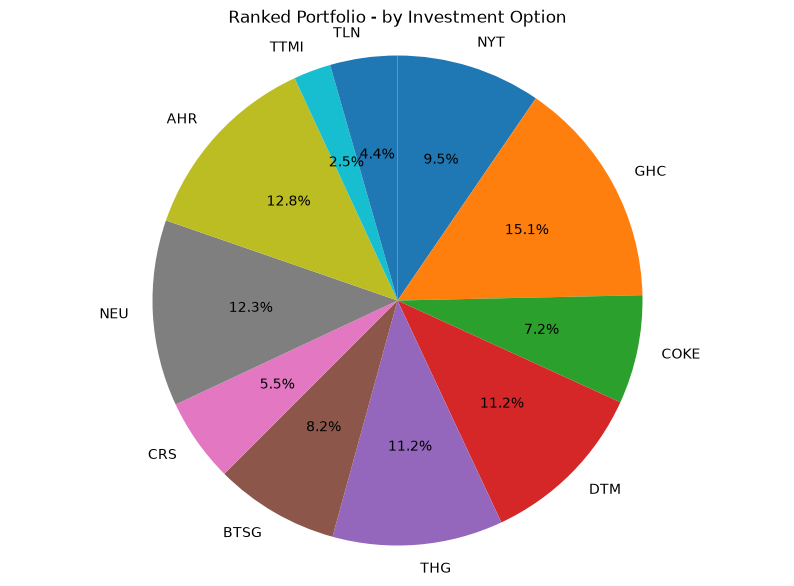

NYT    0.10
GHC    0.15
COKE   0.07
DTM    0.11
THG    0.11
BTSG   0.08
CRS    0.06
NEU    0.12
AHR    0.13
TTMI   0.02
TLN    0.04



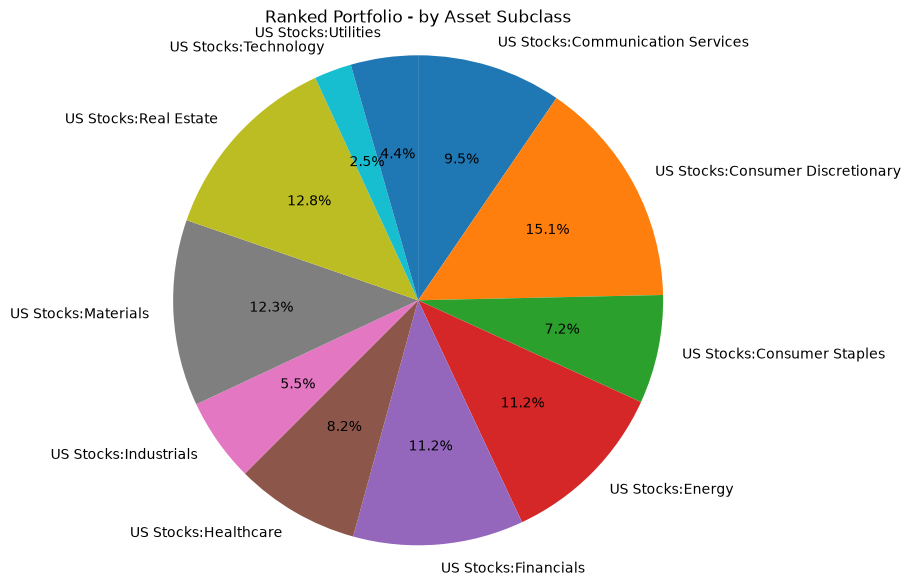

US Stocks:Communication Services   0.10
US Stocks:Consumer Discretionary   0.15
US Stocks:Consumer Staples         0.07
US Stocks:Energy                   0.11
US Stocks:Financials               0.11
US Stocks:Healthcare               0.08
US Stocks:Industrials              0.06
US Stocks:Materials                0.12
US Stocks:Real Estate              0.13
US Stocks:Technology               0.02
US Stocks:Utilities                0.04



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    TLN                            0.0443
    TTMI                           0.0246
    AHR                            0.1280
    NEU                            0.1228
    CRS                            0.0553
    BTSG                           0.0822
    THG                            0.1124
    DTM                            0.1121
    COKE                           0.0716
    GHC                            0.1511
    NYT                            0.0955


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).